In [1]:
import os
print('Working directory:', os.getcwd())

Working directory: E:\.MSc\Research2\Research\Data_Prep_ipynb


# 🔬 HeartCycle — Notebook 2: Signal Extraction & Preprocessing

---

## Purpose
This notebook is **Step 2** of the pipeline. For each usable HDF5 record identified in Notebook 1, we:

1. **Extract** ICG (raw Z → dZ/dt), ECG, and ECHO ground truth
2. **Preprocess** signals: baseline removal → bandpass filter → normalize
3. **Segment** into per-beat windows (200ms pre-R to 800ms post-R)
4. **Detect** ICG B-point and X-point (the biased estimates)
5. **Compute** per-beat bias = ICG estimate − ECHO ground truth
6. **Save** each record as a structured `.npz` file

Each cell is designed to be **run and inspected individually** with rich visualizations so you understand every transformation.

---
**Requires:** `output/master_manifest.csv` from Notebook 1.

In [2]:
DATA_ROOT        = 'E:/.MSc/Research/Data'
MANIFEST_PATH    = './output/master_manifest.csv'
OUTPUT_PREP_DIR  = './output/preprocessed'

import os
os.makedirs(OUTPUT_PREP_DIR, exist_ok=True)
print(f'Config set. Output: {OUTPUT_PREP_DIR}')

Config set. Output: ./output/preprocessed


In [3]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from scipy.signal import butter, sosfiltfilt, detrend, find_peaks
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

# Constants from the HeartCycle paper
FS_NICCOMO  = 200    # Hz — ECG and ICG
FS_ECHO     = 136    # Hz — ECHO
PRE_R_MS    = 200    # ms before R-peak in beat window
POST_R_MS   = 800    # ms after R-peak in beat window
WIN_SAMPLES = int((PRE_R_MS + POST_R_MS) * FS_NICCOMO / 1000)  # = 200 samples
R_IDX       = int(PRE_R_MS * FS_NICCOMO / 1000)                # = 40 (R-peak index in window)

print(f'Window length: {WIN_SAMPLES} samples = {PRE_R_MS+POST_R_MS}ms at {FS_NICCOMO}Hz')
print(f'R-peak at sample index {R_IDX} within window')

manifest = pd.read_csv(MANIFEST_PATH)
usable   = manifest[manifest['complete'] == True].reset_index(drop=True)
print(f'\nUsable records loaded: {len(usable)}')

Window length: 200 samples = 1000ms at 200Hz
R-peak at sample index 40 within window

Usable records loaded: 212


## 1. ICG: Raw Z → dZ/dt
The Niccomo device stores **raw thoracic impedance Z** (in Ohm). For ICG analysis,
we need **dZ/dt** (the derivative) — this is the actual waveform that shows the ABEXYOZ complex.

We use `np.gradient` with the **actual time vector** (not assumed 200 Hz) for accuracy.

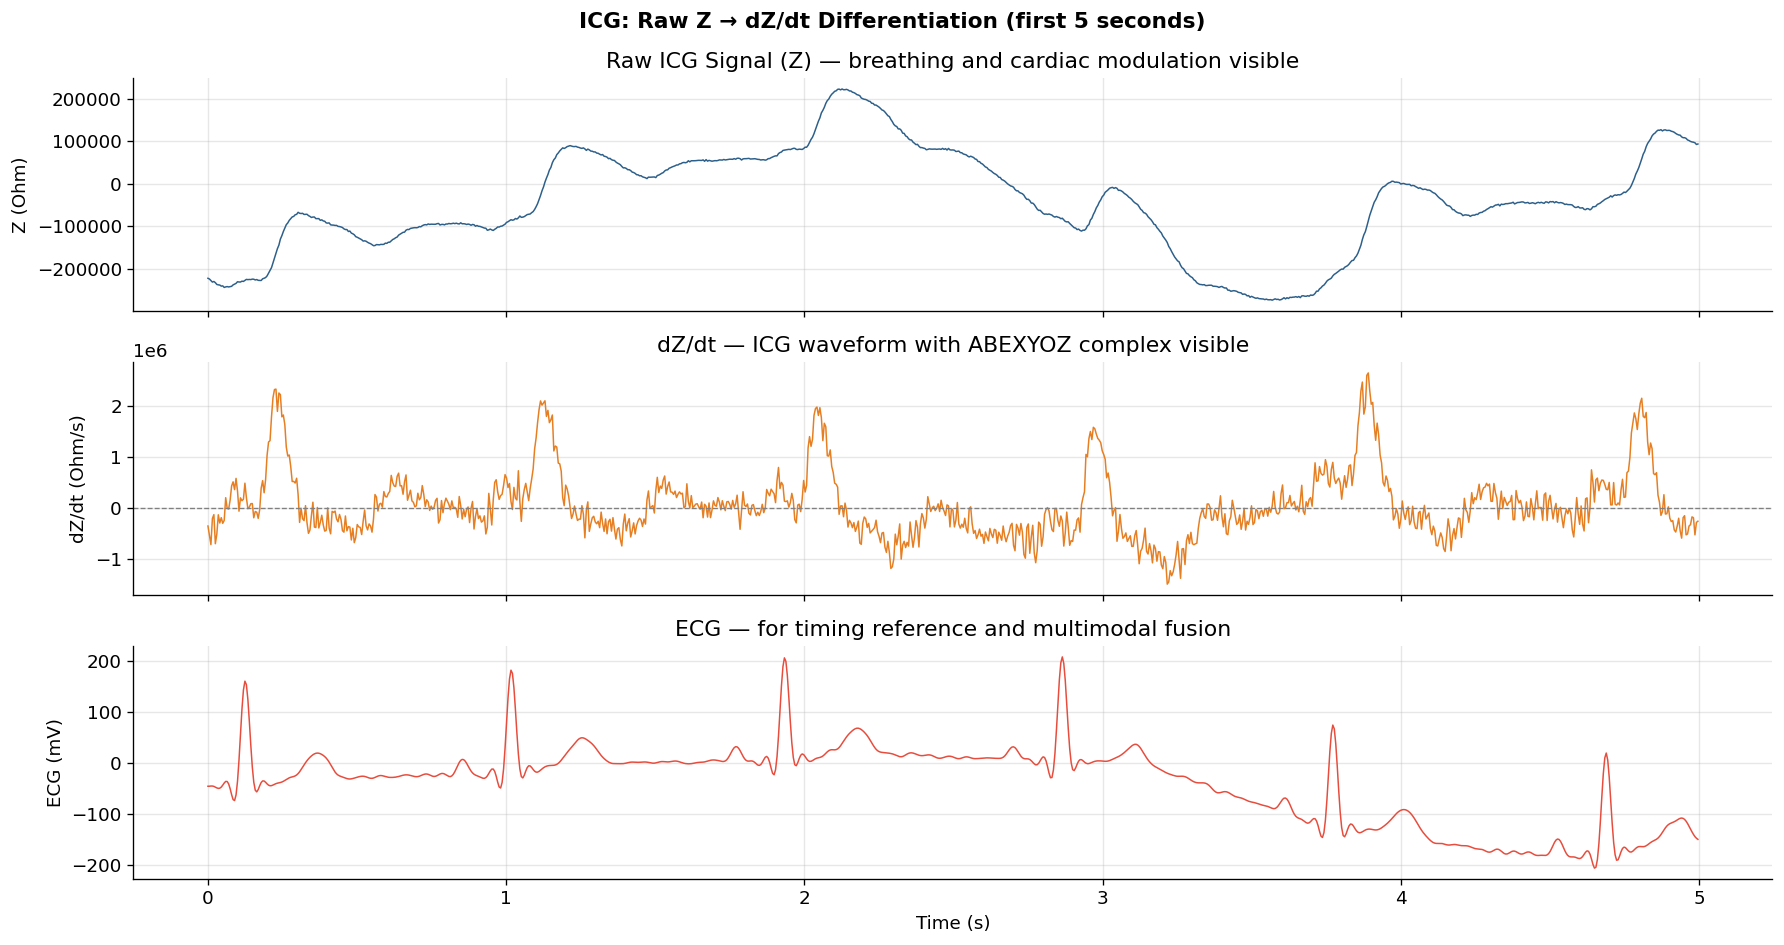

Actual sampling interval: 4.956 ms  (nominal: 5.0 ms at 200 Hz)


In [4]:
# Load a sample file to demonstrate the differentiation
sample_path = usable.iloc[0]['filepath']

with h5py.File(sample_path, 'r') as f:
    icg_raw  = f['measure']['value']['_031']['value']['data']['value'][()]
    icg_time = f['measure']['value']['_031']['value']['time']['value'][()]
    ecg_raw  = f['measure']['value']['_030']['value']['data']['value'][()]
    ecg_time = f['measure']['value']['_030']['value']['time']['value'][()]

icg  = icg_raw[0]  if icg_raw.ndim  == 2 else icg_raw
t_icg = (icg_time[0] if icg_time.ndim == 2 else icg_time).astype(np.float64) * 1000.0
ecg  = ecg_raw[0]  if ecg_raw.ndim  == 2 else ecg_raw
t_ecg = (ecg_time[0] if ecg_time.ndim == 2 else ecg_time).astype(np.float64) * 1000.0

# THE CRITICAL STEP: differentiate with actual dt
dt_s  = np.mean(np.diff(t_icg)) / 1000.0  # ms → seconds
dzdt  = np.gradient(icg, dt_s)

# Zoom to 5 seconds for clarity
t0 = t_icg[0]
mask = (t_icg >= t0) & (t_icg < t0 + 5000)

fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
fig.suptitle('ICG: Raw Z → dZ/dt Differentiation (first 5 seconds)', fontsize=13, fontweight='bold')

axes[0].plot((t_icg[mask]-t0)/1000, icg[mask], color='#2C5F8A', linewidth=0.9)
axes[0].set_ylabel('Z (Ohm)')
axes[0].set_title('Raw ICG Signal (Z) — breathing and cardiac modulation visible')

axes[1].plot((t_icg[mask]-t0)/1000, dzdt[mask], color='#E67E22', linewidth=0.9)
axes[1].set_ylabel('dZ/dt (Ohm/s)')
axes[1].set_title('dZ/dt — ICG waveform with ABEXYOZ complex visible')
axes[1].axhline(0, color='gray', linewidth=0.8, linestyle='--')

mask_ecg = (t_ecg >= t0) & (t_ecg < t0 + 5000)
axes[2].plot((t_ecg[mask_ecg]-t0)/1000, ecg[mask_ecg], color='#E74C3C', linewidth=0.9)
axes[2].set_ylabel('ECG (mV)')
axes[2].set_xlabel('Time (s)')
axes[2].set_title('ECG — for timing reference and multimodal fusion')

plt.tight_layout()
plt.show()

print(f'Actual sampling interval: {dt_s*1000:.3f} ms  (nominal: {1000/FS_NICCOMO:.1f} ms at {FS_NICCOMO} Hz)')

## 2. Signal Preprocessing: Filter Chain
Both ICG dZ/dt and ECG go through the same preprocessing chain:
1. **Baseline wander removal** (linear detrend)
2. **Bandpass filter** (0.5–40 Hz, 4th-order Butterworth, zero-phase)
3. **Per-beat Z-score normalization** (applied later during windowing)

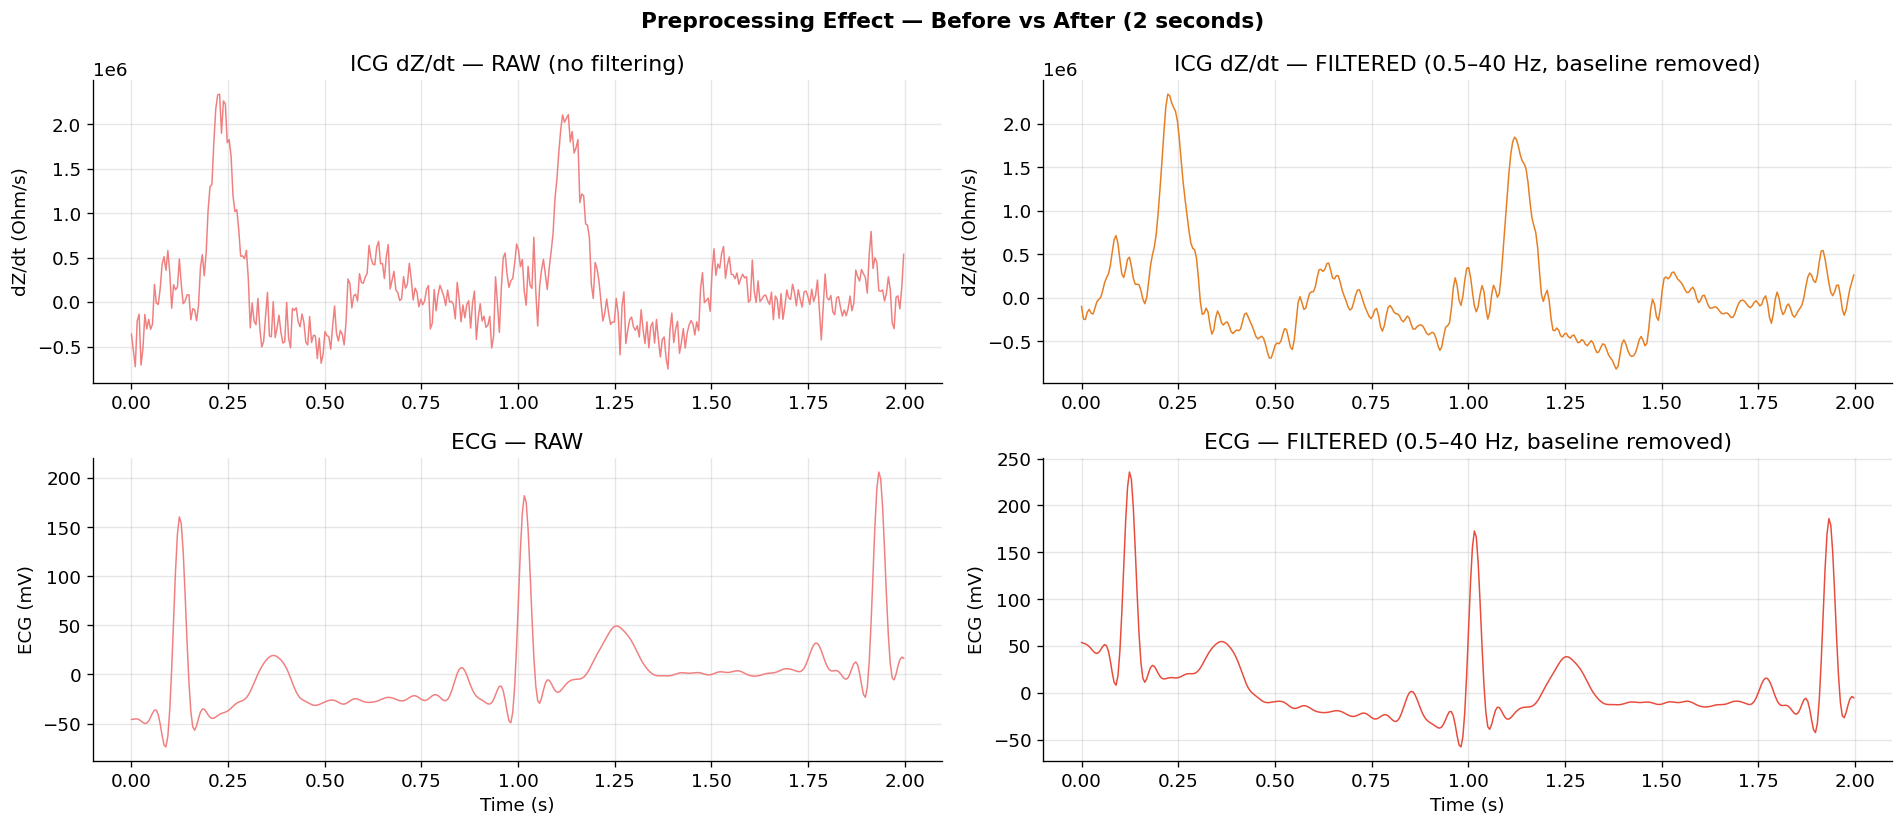

In [5]:
def butter_bandpass_sos(lowcut, highcut, fs, order=4):
    nyq = fs / 2.0
    return butter(order, [lowcut/nyq, highcut/nyq], btype='band', output='sos')

def preprocess_signal(signal, fs, lowcut=0.5, highcut=40.0):
    """Full preprocessing: detrend → bandpass filter."""
    s = detrend(signal, type='linear')            # Step 1: baseline wander
    sos = butter_bandpass_sos(lowcut, highcut, fs) # Step 2: bandpass filter
    s = sosfiltfilt(sos, s)                        # zero-phase filtering
    return s

dzdt_filt = preprocess_signal(dzdt, FS_NICCOMO)
ecg_filt  = preprocess_signal(ecg,  FS_NICCOMO)

# Visualize before vs after (2-second window)
mask_s = (t_icg >= t0) & (t_icg < t0 + 2000)
mask_ecg_s = (t_ecg >= t0) & (t_ecg < t0 + 2000)

fig, axes = plt.subplots(2, 2, figsize=(16, 7))
fig.suptitle('Preprocessing Effect — Before vs After (2 seconds)', fontsize=13, fontweight='bold')

axes[0,0].plot((t_icg[mask_s]-t0)/1000, dzdt[mask_s], color='lightcoral', linewidth=0.9)
axes[0,0].set_title('ICG dZ/dt — RAW (no filtering)')
axes[0,0].set_ylabel('dZ/dt (Ohm/s)')

axes[0,1].plot((t_icg[mask_s]-t0)/1000, dzdt_filt[mask_s], color='#E67E22', linewidth=0.9)
axes[0,1].set_title('ICG dZ/dt — FILTERED (0.5–40 Hz, baseline removed)')
axes[0,1].set_ylabel('dZ/dt (Ohm/s)')

axes[1,0].plot((t_ecg[mask_ecg_s]-t0)/1000, ecg[mask_ecg_s], color='lightcoral', linewidth=0.9)
axes[1,0].set_title('ECG — RAW')
axes[1,0].set_ylabel('ECG (mV)')
axes[1,0].set_xlabel('Time (s)')

axes[1,1].plot((t_ecg[mask_ecg_s]-t0)/1000, ecg_filt[mask_ecg_s], color='#E74C3C', linewidth=0.9)
axes[1,1].set_title('ECG — FILTERED (0.5–40 Hz, baseline removed)')
axes[1,1].set_ylabel('ECG (mV)')
axes[1,1].set_xlabel('Time (s)')

plt.tight_layout()
plt.show()

## 3. Beat Segmentation
We extract **one window per cardiac cycle**, centered on the R-peak:
- **200ms before R-peak** (captures ECG P-wave, QRS onset)
- **800ms after R-peak** (captures full ICG systolic complex: B, C, X points)
- Total window: 1000ms = 200 samples at 200 Hz

In [6]:
# Load R-peak timestamps and ECHO ground truth
with h5py.File(sample_path, 'r') as f:
    r_data = f['measure']['value']['_032']['value']['data']['value'][()]
    r_peaks_ms = r_data.flatten().astype(np.float64) * 1000.0   # seconds → ms
    
    avo_echo  = f['measure']['value']['_093']['value']['data']['value'][()].flatten().astype(np.float64) * 1000.0
    avc_echo  = f['measure']['value']['_095']['value']['data']['value'][()].flatten().astype(np.float64) * 1000.0
    pep_echo  = f['measure']['value']['_094']['value']['data']['value'][()].flatten().astype(np.float64)
    lvet_echo = f['measure']['value']['_096']['value']['data']['value'][()].flatten().astype(np.float64)

print('r_peaks:', len(r_peaks_ms))
print('avo_echo:', len(avo_echo), '| pep_echo:', len(pep_echo))
print('avc_echo:', len(avc_echo), '| lvet_echo:', len(lvet_echo))

print(f'R-peaks detected:  {len(r_peaks_ms)}')
print(f'ECHO AVO events:   {len(avo_echo)}')
print(f'ECHO AVC events:   {len(avc_echo)}')
print(f'PEP values (ms):   {pep_echo[:5]}')
print(f'LVET values (ms):  {lvet_echo[:5]}')
print(f'Event lengths: avo={len(avo_echo)}, pep={len(pep_echo)}, avc={len(avc_echo)}, lvet={len(lvet_echo)}, r_peaks={len(r_peaks_ms)}')


# Compute RR intervals (heart rate estimate)
rr_intervals = np.diff(r_peaks_ms)
print(f'\nMean RR interval: {np.mean(rr_intervals):.0f}ms  →  Heart rate: {60000/np.mean(rr_intervals):.0f} bpm')
print(f'Our post-R window ({POST_R_MS}ms) covers {100*POST_R_MS/np.mean(rr_intervals):.0f}% of a typical beat')

r_peaks: 9
avo_echo: 2 | pep_echo: 2
avc_echo: 2 | lvet_echo: 2
R-peaks detected:  9
ECHO AVO events:   2
ECHO AVC events:   2
PEP values (ms):   [0. 0.]
LVET values (ms):  [0. 0.]
Event lengths: avo=2, pep=2, avc=2, lvet=2, r_peaks=9

Mean RR interval: 911ms  →  Heart rate: 66 bpm
Our post-R window (800ms) covers 88% of a typical beat


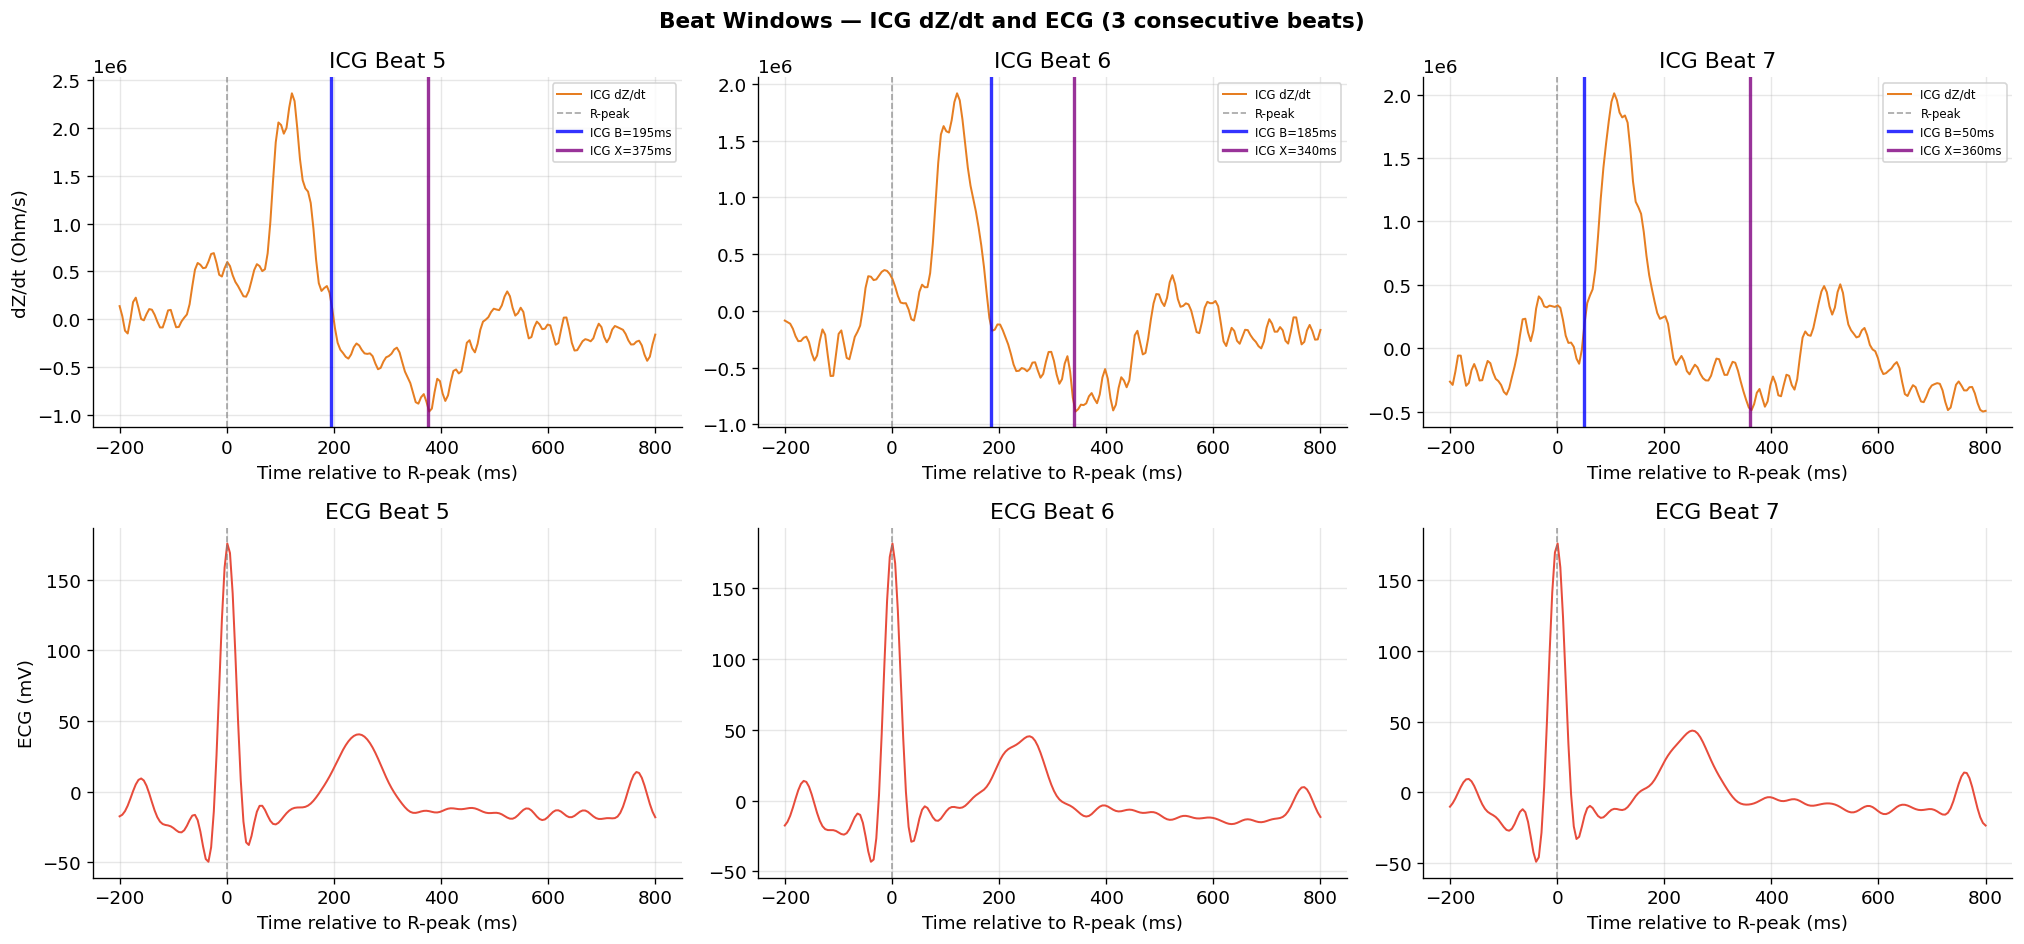

The dashed vertical lines show:
  Blue   = ICG B-point (estimated AVO) — potentially BIASED
  Purple = ICG X-point (estimated AVC) — potentially BIASED
  Green  = ECHO AVO (TRUE valve opening) — GROUND TRUTH
  Red    = ECHO AVC (TRUE valve closing) — GROUND TRUTH

The gap between ICG and ECHO lines = BIAS we want the model to correct!


In [7]:
# Demonstrate beat window extraction on 3 consecutive beats
win_pre  = int(PRE_R_MS  * FS_NICCOMO / 1000)   # 40 samples
win_post = int(POST_R_MS * FS_NICCOMO / 1000)   # 160 samples
win_len  = win_pre + win_post                    # 200 samples
t_window = np.linspace(-PRE_R_MS, POST_R_MS, win_len)  # ms relative to R-peak

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
fig.suptitle('Beat Windows — ICG dZ/dt and ECG (3 consecutive beats)', fontsize=13, fontweight='bold')

# Use beats from the middle of the recording (more stable)
mid = len(r_peaks_ms) // 2
beat_indices = [mid, mid+1, mid+2]

for col_i, bi in enumerate(beat_indices):
    r_ms  = r_peaks_ms[bi]
    r_idx = np.searchsorted(t_icg, r_ms)
    start = r_idx - win_pre
    end   = r_idx + win_post
    
    if start < 0 or end > len(dzdt_filt):
        continue
    
    icg_win = dzdt_filt[start:end]
    
    # Match ECG to same time window
    r_ecg_idx = np.searchsorted(t_ecg, r_ms)
    e_start = r_ecg_idx - win_pre
    e_end   = r_ecg_idx + win_post
    if e_start < 0 or e_end > len(ecg_filt):
        continue
    ecg_win = ecg_filt[e_start:e_end]
    if len(ecg_win) != win_len:
        ecg_win = np.interp(np.linspace(0, 1, win_len), np.linspace(0, 1, len(ecg_win)), ecg_win)
    
    # Nearest ECHO AVO and AVC to this R-peak
    gt_avo_rel = None
    gt_avc_rel = None
    if len(avo_echo) > 0:
        diffs = np.abs(avo_echo - r_ms)
        nearest = np.argmin(diffs)
        if diffs[nearest] < 500:
            gt_avo_rel = float(avo_echo[nearest] - r_ms)
    if len(avc_echo) > 0:
        diffs = np.abs(avc_echo - r_ms)
        nearest = np.argmin(diffs)
        if diffs[nearest] < 800:
            gt_avc_rel = float(avc_echo[nearest] - r_ms)
    
    # ICG characteristic points (simple detection)
    b_lo = win_pre + int(0.05 * FS_NICCOMO)
    b_hi = win_pre + int(0.20 * FS_NICCOMO)
    x_lo = win_pre + int(0.20 * FS_NICCOMO)
    x_hi = win_pre + int(0.50 * FS_NICCOMO)
    icg_b_rel = (np.argmin(icg_win[b_lo:b_hi]) + b_lo - win_pre) * (1000/FS_NICCOMO)
    icg_x_rel = (np.argmin(icg_win[x_lo:x_hi]) + x_lo - win_pre) * (1000/FS_NICCOMO)
    
    # ICG dZ/dt window
    ax = axes[0, col_i]
    ax.plot(t_window, icg_win, color='#E67E22', linewidth=1.2, label='ICG dZ/dt')
    ax.axvline(0, color='gray', linewidth=1, linestyle='--', alpha=0.7, label='R-peak')
    ax.axvline(icg_b_rel, color='blue', linewidth=2, linestyle='-', label=f'ICG B={icg_b_rel:.0f}ms', alpha=0.8)
    ax.axvline(icg_x_rel, color='purple', linewidth=2, linestyle='-', label=f'ICG X={icg_x_rel:.0f}ms', alpha=0.8)
    if gt_avo_rel is not None:
        ax.axvline(gt_avo_rel, color='#27AE60', linewidth=2.5, linestyle=':', label=f'ECHO AVO={gt_avo_rel:.0f}ms')
    if gt_avc_rel is not None:
        ax.axvline(gt_avc_rel, color='#E74C3C', linewidth=2.5, linestyle=':', label=f'ECHO AVC={gt_avc_rel:.0f}ms')
    ax.set_xlabel('Time relative to R-peak (ms)')
    ax.set_title(f'ICG Beat {bi+1}')
    if col_i == 0:
        ax.set_ylabel('dZ/dt (Ohm/s)')
    ax.legend(fontsize=7, loc='upper right')
    
    # ECG window
    ax2 = axes[1, col_i]
    ax2.plot(t_window, ecg_win, color='#E74C3C', linewidth=1.2)
    ax2.axvline(0, color='gray', linewidth=1, linestyle='--', alpha=0.7, label='R-peak')
    ax2.set_xlabel('Time relative to R-peak (ms)')
    ax2.set_title(f'ECG Beat {bi+1}')
    if col_i == 0:
        ax2.set_ylabel('ECG (mV)')

plt.tight_layout()
plt.show()

print('The dashed vertical lines show:')
print('  Blue   = ICG B-point (estimated AVO) — potentially BIASED')
print('  Purple = ICG X-point (estimated AVC) — potentially BIASED')
print('  Green  = ECHO AVO (TRUE valve opening) — GROUND TRUTH')
print('  Red    = ECHO AVC (TRUE valve closing) — GROUND TRUTH')
print('\nThe gap between ICG and ECHO lines = BIAS we want the model to correct!')

## 4. Per-Beat Z-Score Normalization
Each beat window is normalized independently (mean=0, std=1). This ensures
the model is invariant to absolute amplitude differences between subjects and sessions.

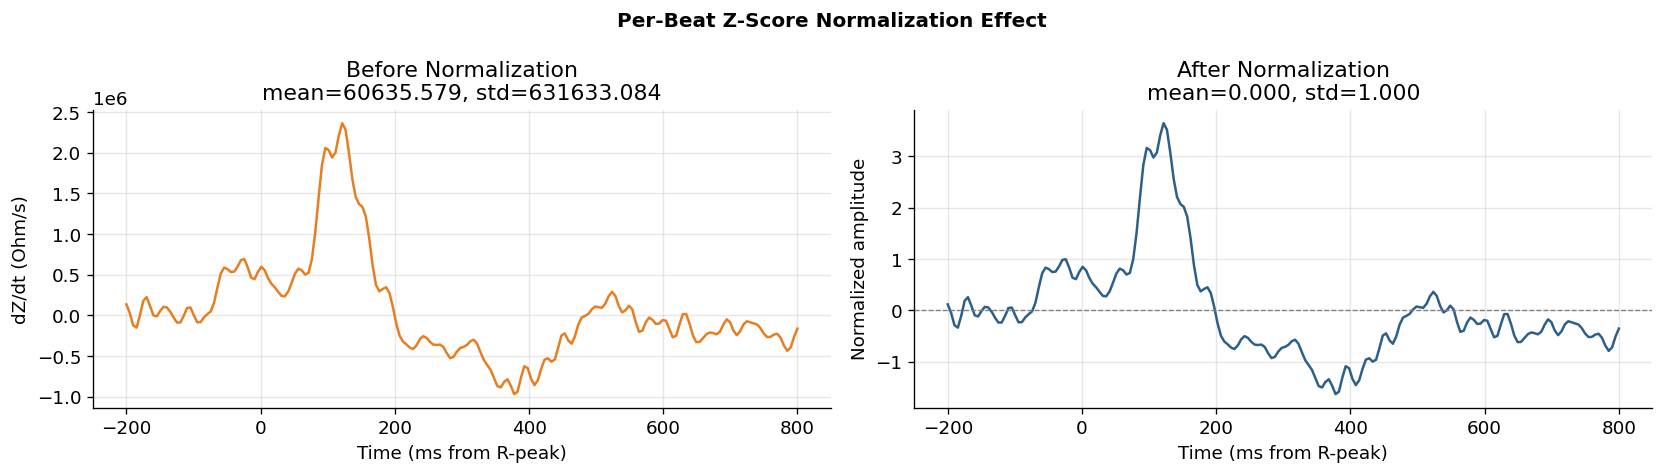

Shape preserved — only amplitude scale changes. Morphology identical.


In [8]:
# Extract one beat to demonstrate normalization
r_ms  = r_peaks_ms[mid]
r_idx = np.searchsorted(t_icg, r_ms)
start, end = r_idx - win_pre, r_idx + win_post
icg_win_raw = dzdt_filt[start:end]

# Z-score normalize
icg_win_norm = (icg_win_raw - np.mean(icg_win_raw)) / (np.std(icg_win_raw) + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Per-Beat Z-Score Normalization Effect', fontsize=12, fontweight='bold')

axes[0].plot(t_window, icg_win_raw,  color='#E67E22')
axes[0].set_title(f'Before Normalization\nmean={np.mean(icg_win_raw):.3f}, std={np.std(icg_win_raw):.3f}')
axes[0].set_xlabel('Time (ms from R-peak)')
axes[0].set_ylabel('dZ/dt (Ohm/s)')

axes[1].plot(t_window, icg_win_norm, color='#2C5F8A')
axes[1].set_title(f'After Normalization\nmean={np.mean(icg_win_norm):.3f}, std={np.std(icg_win_norm):.3f}')
axes[1].set_xlabel('Time (ms from R-peak)')
axes[1].set_ylabel('Normalized amplitude')
axes[1].axhline(0, color='gray', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.show()
print('Shape preserved — only amplitude scale changes. Morphology identical.')

## 5. Full Preprocessing Pipeline (Single Record)

In [9]:
def process_single_record(h5_path, save_dir=None, verbose=True):
    """
    Complete preprocessing pipeline for one HDF5 file.
    Returns a dict with all extracted arrays, or saves .npz if save_dir given.
    """
    h5_path = Path(h5_path)
    stem = h5_path.stem
    parts = stem.split('_')
    subject_id  = f'CHC{parts[0][2:]}' if parts[0].startswith('CH') else parts[0]
    record_id  = parts[2] if len(parts) > 2 else stem
    
    result = {'subject_id': subject_id, 'record_id': record_id, 'status': 'failed'}
    
    try:
        with h5py.File(h5_path, 'r') as f:
            def safe_load(gid, data_scale=1.0):
                try:
                    d = f['measure']['value'][gid]['value']['data']['value'][()]
                    t = f['measure']['value'][gid]['value']['time']['value'][()]
                    d = d[0] if d.ndim == 2 else d
                    t = t[0] if t.ndim == 2 else t
                    return d.astype(np.float64) * data_scale, t.astype(np.float64) * 1000.0
                except:
                    return None, None
            
            def safe_events(gid, scale=1.0):
                try:
                    return f['measure']['value'][gid]['value']['data']['value'][()].flatten().astype(np.float64) * scale
                except:
                    return None
            
            icg_raw, t_icg  = safe_load('_031')
            ecg_raw, t_ecg  = safe_load('_030')
            r_data, _       = safe_load('_032', data_scale=1000.0)
            avo_echo  = safe_events('_093', scale=1000.0)
            avc_echo  = safe_events('_095', scale=1000.0)
            pep_echo  = safe_events('_094', scale=1.0)
            lvet_echo = safe_events('_096', scale=1.0)
            
            if any(x is None for x in [icg_raw, t_icg, ecg_raw, t_ecg, r_data]):
                result['status'] = 'missing_signals'
                return result
            
            r_peaks_ms = r_data.flatten()
    
    except Exception as e:
        result['status'] = f'load_error: {e}'
        return result
    
    # ── 1. Compute dZ/dt ──
    dt_s = np.mean(np.diff(t_icg)) / 1000.0
    dzdt = np.gradient(icg_raw, dt_s)
    
    # ── 2. Trim to overlap window ──
    t_start = max(t_icg[0], t_ecg[0])
    t_end   = min(t_icg[-1], t_ecg[-1])
    m_icg = (t_icg >= t_start) & (t_icg <= t_end)
    m_ecg = (t_ecg >= t_start) & (t_ecg <= t_end)
    dzdt  = dzdt[m_icg];  t_icg2 = t_icg[m_icg]
    ecg_c = ecg_raw[m_ecg]; t_ecg2 = t_ecg[m_ecg]
    if len(t_icg2) != len(t_ecg2):
        ecg_c = np.interp(t_icg2, t_ecg2, ecg_c)
    common_t = t_icg2
    
    # ── 3. Filter ──
    dzdt_f = preprocess_signal(dzdt, FS_NICCOMO)
    ecg_f  = preprocess_signal(ecg_c, FS_NICCOMO)
    
    # ── 4. Extract beats ──
    beats = []
    w_pre  = int(PRE_R_MS  * FS_NICCOMO / 1000)
    w_post = int(POST_R_MS * FS_NICCOMO / 1000)
    wlen   = w_pre + w_post
    
    for r_ms in r_peaks_ms:
        r_i = np.searchsorted(common_t, r_ms)
        s, e = r_i - w_pre, r_i + w_post
        if s < 0 or e > len(dzdt_f): continue
        
        icg_w = dzdt_f[s:e]
        ecg_w = ecg_f[s:e]
        if len(icg_w) != wlen: continue
        
        # ICG B-point: first local trough 50–200ms after R (the genuine B-notch
        # before the systolic upstroke), not the single most-negative sample in
        # the window. Global argmin was locking onto a late trough near the
        # window edge for some subjects (CHC02/04/09), pinning icg_pep at ~195ms
        # and producing the bimodal PEP-bias split. Fall back to argmin only if
        # no prominent local trough exists.
        blo = r_i + int(0.05*FS_NICCOMO); bhi = r_i + int(0.20*FS_NICCOMO)
        blo, bhi = max(0,blo), min(len(dzdt_f)-1,bhi)
        if bhi > blo:
            seg = dzdt_f[blo:bhi]
            troughs, _ = find_peaks(-seg, prominence=0.05*np.ptp(seg))
            b_abs = blo + (troughs[0] if len(troughs) else np.argmin(seg))
        else:
            b_abs = None
        b_ms  = float(common_t[b_abs]) if b_abs is not None else np.nan
        icg_pep = (b_ms - float(common_t[r_i])) if not np.isnan(b_ms) else np.nan
        if verbose and len(beats) < 2:
            print(f'    r_i={r_i}  blo={blo}  bhi={bhi}  b_abs={b_abs}')
            print(f'    r_ms={r_ms:.2f}  b_ms={b_ms:.2f}  icg_pep={icg_pep:.3f}')
            print(f'    actual sample spacing: {common_t[r_i+1]-common_t[r_i]:.4f}ms '
                  f'(assumed {1000/FS_NICCOMO:.2f}ms if truly {FS_NICCOMO}Hz)')
        
        # ICG X-point (search 200–500ms after R)
        xlo = r_i + int(0.20*FS_NICCOMO); xhi = r_i + int(0.50*FS_NICCOMO)
        xlo, xhi = max(0,xlo), min(len(dzdt_f)-1,xhi)
        x_abs = xlo + np.argmin(dzdt_f[xlo:xhi]) if xhi > xlo else None
        x_ms  = float(common_t[x_abs]) if x_abs is not None else np.nan
        icg_lvet = (x_ms - b_ms) if (not np.isnan(b_ms) and not np.isnan(x_ms)) else np.nan
        
        # ECHO ground truth
        gt_avo = gt_avc = gt_pep = gt_lvet = np.nan
        # AVO: absolute-nearest match. R-peak detection and the AVO annotation can
        # legitimately land a few ms apart in either direction, so a forward-only
        # (diff >= 0) constraint can drop the true event whenever that offset is
        # slightly negative. Absolute-nearest is the safer rule for AVO.
        if avo_echo is not None and len(avo_echo):
            d = np.abs(avo_echo - r_ms); ni = np.argmin(d)
            if d[ni] < 500:
                gt_avo = float(avo_echo[ni])
                gt_pep = float(pep_echo[ni]) if (pep_echo is not None and ni < len(pep_echo)) else gt_avo - r_ms
        # AVC: forward-only match. Here the absolute-nearest match really was
        # pulling in the previous beat's event (CHC01 investigation), so the
        # forward-only constraint is correct for AVC specifically.
        if avc_echo is not None and len(avc_echo):
            diffs = avc_echo - r_ms
            fwd = diffs >= 0
            if fwd.any():
                fwd_d, fwd_idx = diffs[fwd], np.where(fwd)[0]
                local_ni = np.argmin(fwd_d)
                ni = fwd_idx[local_ni]
                if fwd_d[local_ni] < 400:
                    gt_avc = float(avc_echo[ni])
                    if lvet_echo is not None and ni < len(lvet_echo):
                        gt_lvet = float(lvet_echo[ni])
        
        # Biases
        b_bias  = (b_ms - gt_avo) if (not np.isnan(b_ms) and not np.isnan(gt_avo)) else np.nan
        x_bias  = (x_ms - gt_avc) if (not np.isnan(x_ms) and not np.isnan(gt_avc)) else np.nan
        pep_bias = (icg_pep - gt_pep) if (not np.isnan(icg_pep) and not np.isnan(gt_pep)) else np.nan
        lvet_bias = (icg_lvet - gt_lvet) if (not np.isnan(icg_lvet) and not np.isnan(gt_lvet)) else np.nan
        
        # Normalize windows
        icg_n = (icg_w - icg_w.mean()) / (icg_w.std() + 1e-8)
        ecg_n = (ecg_w - ecg_w.mean()) / (ecg_w.std() + 1e-8)
        
        beats.append({
            'icg_window': icg_n.astype(np.float32),
            'ecg_window': ecg_n.astype(np.float32),
            'icg_raw_window': icg_w.astype(np.float32),
            'ecg_raw_window': ecg_w.astype(np.float32),
            'r_peak_ms': float(r_ms),
            'gt_pep_ms': float(gt_pep), 'gt_lvet_ms': float(gt_lvet),
            'gt_avo_ms': float(gt_avo), 'gt_avc_ms': float(gt_avc),
            'icg_pep_ms': float(icg_pep) if not np.isnan(icg_pep) else -1.0,
            'icg_lvet_ms': float(icg_lvet) if not np.isnan(icg_lvet) else -1.0,
            'b_bias_ms': float(b_bias) if not np.isnan(b_bias) else np.nan,
            'x_bias_ms': float(x_bias) if not np.isnan(x_bias) else np.nan,
            'pep_bias_ms': float(pep_bias) if not np.isnan(pep_bias) else np.nan,
            'lvet_bias_ms': float(lvet_bias) if not np.isnan(lvet_bias) else np.nan,
            'r_in_win': int(w_pre),
            'b_in_win': int(b_abs - s) if b_abs is not None else -1,
            'x_in_win': int(x_abs - s) if x_abs is not None else -1,
        })
    
    if not beats:
        result['status'] = 'no_beats'
        return result
    
    n = len(beats)
    icg_wins   = np.stack([b['icg_window'] for b in beats])
    ecg_wins   = np.stack([b['ecg_window'] for b in beats])
    multimodal = np.stack([icg_wins, ecg_wins], axis=1)
    labels     = np.array([[b['gt_pep_ms'], b['gt_lvet_ms'], b['gt_avo_ms'], b['gt_avc_ms']] for b in beats], dtype=np.float32)
    icg_ests   = np.array([[b['icg_pep_ms'], b['icg_lvet_ms']] for b in beats], dtype=np.float32)
    biases     = np.array([[b['b_bias_ms'], b['x_bias_ms'], b['pep_bias_ms'], b['lvet_bias_ms']] for b in beats], dtype=np.float32)
    cp_idx     = np.array([[b['r_in_win'], b['b_in_win'], b['x_in_win']] for b in beats], dtype=np.int32)
    r_times    = np.array([b['r_peak_ms'] for b in beats], dtype=np.float32)
    
    if save_dir:
        save_path = Path(save_dir) / f'{subject_id}_{record_id}.npz'
        np.savez_compressed(save_path,
            icg_windows=icg_wins, ecg_windows=ecg_wins, multimodal=multimodal,
            labels=labels, icg_estimates=icg_ests, biases=biases,
            cp_indices=cp_idx, r_times=r_times,
            subject_id=np.array(subject_id), record_id=np.array(record_id))
    
    valid_b = biases[:, 0][~np.isnan(biases[:, 0])]
    valid_x = biases[:, 1][~np.isnan(biases[:, 1])]
    result.update({
        'status': 'ok', 'n_beats': n,
        'multimodal': multimodal, 'labels': labels,
        'biases': biases, 'cp_indices': cp_idx,
        'mean_b_bias': np.nanmean(valid_b) if len(valid_b) else np.nan,
        'mean_x_bias': np.nanmean(valid_x) if len(valid_x) else np.nan,
    })
    
    if verbose:
        print(f'✅ {subject_id} {record_id}: {n} beats | '
              f'B-bias={result["mean_b_bias"]:.1f}ms | '
              f'X-bias={result["mean_x_bias"]:.1f}ms')
    return result

## 6. Inspect Output Arrays from a Single Record

In [10]:
test_result = process_single_record(sample_path, save_dir=None, verbose=True)
if test_result.get('status') != 'ok':
    raise RuntimeError(f"Single-record preprocessing failed: {test_result.get('status')}")

mm   = test_result['multimodal']  # (N, 2, 200)
labs = test_result['labels']       # (N, 4)
bias = test_result['biases']       # (N, 4)
cp   = test_result['cp_indices']   # (N, 3)

print('=== ARRAY CONTENTS INSPECTION ===')
print(f'\nmultimodal[0, 0, :] = ICG channel, beat 0:')
print(f'  shape: {mm[0,0,:].shape}')
print(f'  mean={mm[0,0,:].mean():.3f}  std={mm[0,0,:].std():.3f}  (should be ~0, ~1 after normalization)')

print(f'\nmultimodal[0, 1, :] = ECG channel, beat 0:')
print(f'  mean={mm[0,1,:].mean():.3f}  std={mm[0,1,:].std():.3f}')

valid_labs = labs[(labs[:,0] > 0) & (labs[:,1] > 0)]
print(f'\nLabels (first 5 valid beats):')
print(f'  Columns: [PEP_ms, LVET_ms, AVO_ms, AVC_ms]')
print(valid_labs[:5])

valid_bias = bias[~np.isnan(bias[:,0])]
if len(valid_bias) > 0:
    print(f'\nBiases (first 5 valid beats):')
    print(f'  Columns: [B_point_bias_ms, X_point_bias_ms, PEP_bias_ms, LVET_bias_ms]')
    print(valid_bias[:5])

print(f'\nCharacteristic point positions (first 5 beats):')
print(f'  Columns: [R_idx_in_window, B_idx_in_window, X_idx_in_window]')
print(cp[:5])
print(f'  R-peak is always at index {R_IDX} (= {PRE_R_MS}ms pre-window at {FS_NICCOMO}Hz)')

    r_i=205  blo=215  bhi=245  b_abs=217
    r_ms=1025.76  b_ms=1085.23  icg_pep=59.470
    actual sample spacing: 4.9558ms (assumed 5.00ms if truly 200Hz)
    r_i=390  blo=400  bhi=430  b_abs=400
    r_ms=1942.59  b_ms=1992.15  icg_pep=49.558
    actual sample spacing: 4.9558ms (assumed 5.00ms if truly 200Hz)
✅ CHC07 s0000029: 7 beats | B-bias=nanms | X-bias=nanms
=== ARRAY CONTENTS INSPECTION ===

multimodal[0, 0, :] = ICG channel, beat 0:
  shape: (200,)
  mean=0.000  std=1.000  (should be ~0, ~1 after normalization)

multimodal[0, 1, :] = ECG channel, beat 0:
  mean=-0.000  std=1.000

Labels (first 5 valid beats):
  Columns: [PEP_ms, LVET_ms, AVO_ms, AVC_ms]
[]

Characteristic point positions (first 5 beats):
  Columns: [R_idx_in_window, B_idx_in_window, X_idx_in_window]
[[ 40  52 114]
 [ 40  50 113]
 [ 40  78 113]
 [ 40  61 115]
 [ 40  77 108]]
  R-peak is always at index 40 (= 200ms pre-window at 200Hz)


In [11]:
print('gt_avo_ms:', test_result['labels'][:, 2])
print('gt_avc_ms:', test_result['labels'][:, 3])
print('Equal?', np.allclose(test_result['labels'][:, 2], test_result['labels'][:, 3], equal_nan=True))

gt_avo_ms: [nan nan nan nan nan nan nan]
gt_avc_ms: [nan nan nan nan nan nan nan]
Equal? True


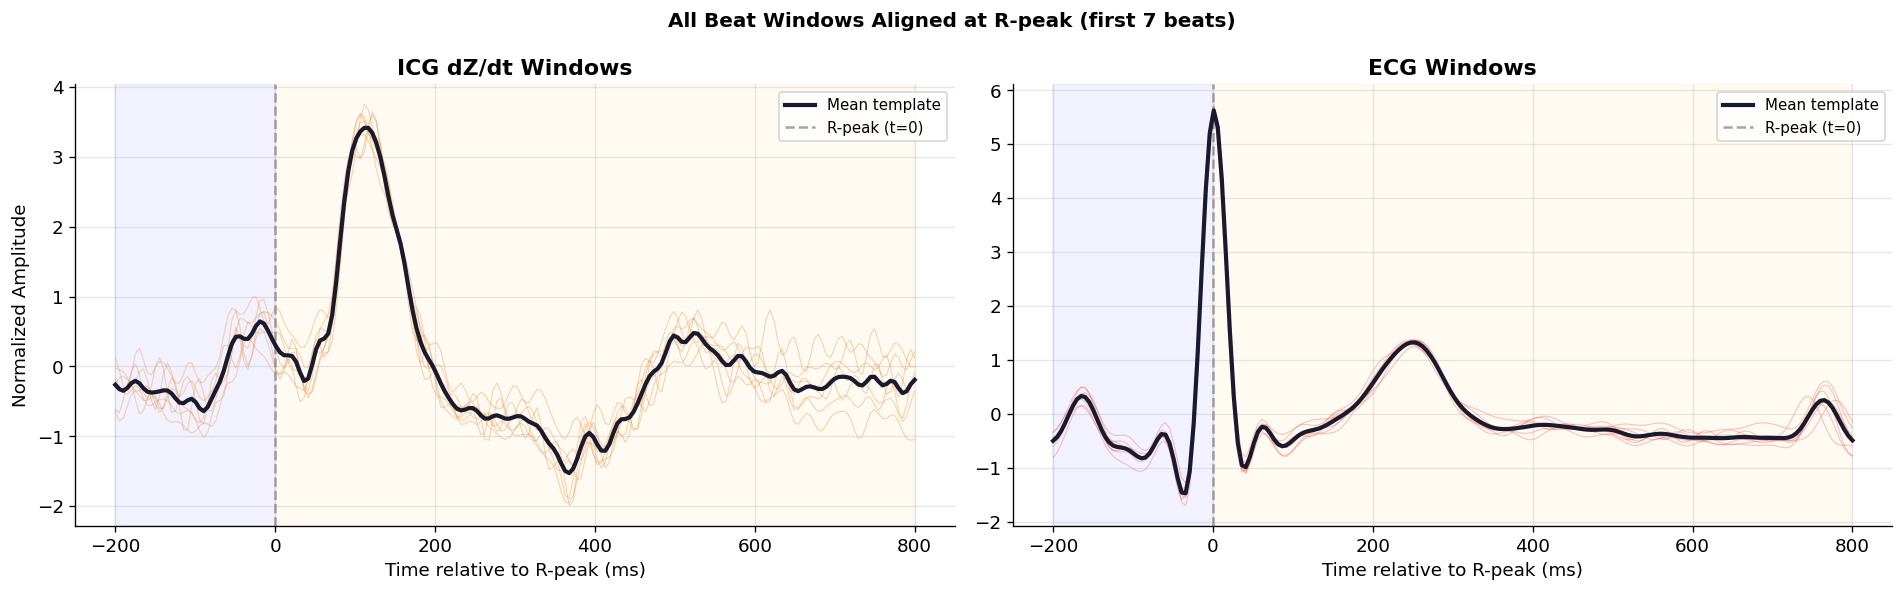

In [12]:
# Visualize all beat windows aligned at R-peak
mm = test_result['multimodal']
n_beats = min(mm.shape[0], 20)  # Show up to 20 beats
t_win = np.linspace(-PRE_R_MS, POST_R_MS, WIN_SAMPLES)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(f'All Beat Windows Aligned at R-peak (first {n_beats} beats)', fontsize=12, fontweight='bold')

for i in range(n_beats):
    alpha = 0.3 if n_beats > 5 else 0.6
    axes[0].plot(t_win, mm[i, 0, :], alpha=alpha, linewidth=0.7, color='#E67E22')
    axes[1].plot(t_win, mm[i, 1, :], alpha=alpha, linewidth=0.7, color='#E74C3C')

# Mean template
axes[0].plot(t_win, mm[:n_beats, 0, :].mean(axis=0), color='#1A1A2E', linewidth=2.5, label='Mean template', zorder=10)
axes[1].plot(t_win, mm[:n_beats, 1, :].mean(axis=0), color='#1A1A2E', linewidth=2.5, label='Mean template', zorder=10)

for ax, title in [(axes[0], 'ICG dZ/dt Windows'), (axes[1], 'ECG Windows')]:
    ax.axvline(0, color='gray', linewidth=1.5, linestyle='--', alpha=0.7, label='R-peak (t=0)')
    ax.set_xlabel('Time relative to R-peak (ms)')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=9)
    ax.axvspan(-PRE_R_MS, 0, alpha=0.05, color='blue')
    ax.axvspan(0, POST_R_MS, alpha=0.05, color='orange')

axes[0].set_ylabel('Normalized Amplitude')
plt.tight_layout()
plt.show()

## 7. Run Full Pipeline on All Usable Records

In [13]:
import time

logs = []
print(f'Processing {len(usable)} records...')
print('-' * 60)
t_start = time.time()

for i, row in usable.iterrows():
    res = process_single_record(row['filepath'], save_dir=OUTPUT_PREP_DIR, verbose=True)
    logs.append({
        'subject_id': row['subject_id'], 'experiment': row['experiment'],
        'record_id':  row['record_id'],  'status': res.get('status'),
        'n_beats':    res.get('n_beats', 0),
        'mean_b_bias_ms': res.get('mean_b_bias', np.nan),
        'mean_x_bias_ms': res.get('mean_x_bias', np.nan),
    })

elapsed = time.time() - t_start
log_df = pd.DataFrame(logs)
log_df.to_csv(f'{OUTPUT_PREP_DIR}/preprocessing_log.csv', index=False)

ok_df = log_df[log_df['status'] == 'ok']
print(f"\n{'='*55}")
print(f'Processing complete in {elapsed:.0f}s')
print(f'  Successful: {len(ok_df)}/{len(log_df)}')
print(f'  Total beats extracted: {ok_df["n_beats"].sum()}')
print(f'  Status counts: {log_df["status"].value_counts().to_dict()}')

Processing 212 records...
------------------------------------------------------------
    r_i=205  blo=215  bhi=245  b_abs=217
    r_ms=1025.76  b_ms=1085.23  icg_pep=59.470
    actual sample spacing: 4.9558ms (assumed 5.00ms if truly 200Hz)
    r_i=390  blo=400  bhi=430  b_abs=400
    r_ms=1942.59  b_ms=1992.15  icg_pep=49.558
    actual sample spacing: 4.9558ms (assumed 5.00ms if truly 200Hz)
✅ CHC07 s0000029: 7 beats | B-bias=nanms | X-bias=nanms
    r_i=198  blo=208  bhi=238  b_abs=237
    r_ms=993.78  b_ms=1187.99  icg_pep=194.213
    actual sample spacing: 4.9798ms (assumed 5.00ms if truly 200Hz)
    r_i=378  blo=388  bhi=418  b_abs=412
    r_ms=1890.15  b_ms=2059.46  icg_pep=169.314
    actual sample spacing: 4.9798ms (assumed 5.00ms if truly 200Hz)
✅ CHC07 s0000030: 7 beats | B-bias=83.7ms | X-bias=nanms
    r_i=52  blo=62  bhi=92  b_abs=62
    r_ms=273.69  b_ms=324.03  icg_pep=50.343
    actual sample spacing: 5.0343ms (assumed 5.00ms if truly 200Hz)
    r_i=214  blo=224  bhi

✅ CHC09 s0000016: 8 beats | B-bias=92.2ms | X-bias=nanms
    r_i=51  blo=61  bhi=91  b_abs=64
    r_ms=267.42  b_ms=332.90  icg_pep=65.472
    actual sample spacing: 5.0363ms (assumed 5.00ms if truly 200Hz)
    r_i=235  blo=245  bhi=275  b_abs=267
    r_ms=1194.10  b_ms=1355.27  icg_pep=161.162
    actual sample spacing: 5.0363ms (assumed 5.00ms if truly 200Hz)
✅ CHC09 s0000017: 8 beats | B-bias=79.3ms | X-bias=40.0ms
    r_i=118  blo=128  bhi=158  b_abs=157
    r_ms=603.97  b_ms=800.49  icg_pep=196.523
    actual sample spacing: 5.0390ms (assumed 5.00ms if truly 200Hz)
    r_i=314  blo=324  bhi=354  b_abs=326
    r_ms=1591.62  b_ms=1652.09  icg_pep=60.469
    actual sample spacing: 5.0390ms (assumed 5.00ms if truly 200Hz)
✅ CHC09 s0000018: 7 beats | B-bias=72.8ms | X-bias=nanms
    r_i=154  blo=164  bhi=194  b_abs=193
    r_ms=786.50  b_ms=982.88  icg_pep=196.377
    actual sample spacing: 5.0353ms (assumed 5.00ms if truly 200Hz)
    r_i=336  blo=346  bhi=376  b_abs=375
    r_ms=1702.

✅ CHC01 s0000072: 4 beats | B-bias=14.5ms | X-bias=nanms
    r_i=82  blo=92  bhi=122  b_abs=95
    r_ms=422.16  b_ms=487.14  icg_pep=64.975
    actual sample spacing: 4.9981ms (assumed 5.00ms if truly 200Hz)
    r_i=237  blo=247  bhi=277  b_abs=251
    r_ms=1196.86  b_ms=1266.84  icg_pep=69.973
    actual sample spacing: 4.9981ms (assumed 5.00ms if truly 200Hz)
✅ CHC01 s0000073: 4 beats | B-bias=8.8ms | X-bias=nanms
    r_i=61  blo=71  bhi=101  b_abs=72
    r_ms=314.33  b_ms=369.27  icg_pep=54.939
    actual sample spacing: 4.9945ms (assumed 5.00ms if truly 200Hz)
    r_i=222  blo=232  bhi=262  b_abs=237
    r_ms=1118.43  b_ms=1193.35  icg_pep=74.917
    actual sample spacing: 4.9945ms (assumed 5.00ms if truly 200Hz)
✅ CHC01 s0000074: 4 beats | B-bias=10.0ms | X-bias=nanms
    r_i=84  blo=94  bhi=124  b_abs=99
    r_ms=432.17  b_ms=507.49  icg_pep=75.321
    actual sample spacing: 5.0214ms (assumed 5.00ms if truly 200Hz)
    r_i=221  blo=231  bhi=261  b_abs=235
    r_ms=1120.10  b_ms=1

    r_i=153  blo=163  bhi=193  b_abs=192
    r_ms=772.14  b_ms=967.80  icg_pep=195.657
    actual sample spacing: 5.0168ms (assumed 5.00ms if truly 200Hz)
    r_i=293  blo=303  bhi=333  b_abs=332
    r_ms=1474.50  b_ms=1670.16  icg_pep=195.657
    actual sample spacing: 5.0168ms (assumed 5.00ms if truly 200Hz)
✅ CHC02 s0000056: 10 beats | B-bias=146.1ms | X-bias=8.6ms
    r_i=40  blo=50  bhi=80  b_abs=78
    r_ms=204.49  b_ms=395.16  icg_pep=190.662
    actual sample spacing: 5.0174ms (assumed 5.00ms if truly 200Hz)
    r_i=182  blo=192  bhi=222  b_abs=194
    r_ms=916.97  b_ms=977.18  icg_pep=60.209
    actual sample spacing: 5.0174ms (assumed 5.00ms if truly 200Hz)
✅ CHC02 s0000057: 10 beats | B-bias=128.4ms | X-bias=5.9ms
    r_i=151  blo=161  bhi=191  b_abs=175
    r_ms=764.42  b_ms=884.80  icg_pep=120.379
    actual sample spacing: 5.0158ms (assumed 5.00ms if truly 200Hz)
    r_i=324  blo=334  bhi=364  b_abs=347
    r_ms=1632.15  b_ms=1747.52  icg_pep=115.363
    actual sample spa

    r_i=156  blo=166  bhi=196  b_abs=195
    r_ms=787.37  b_ms=983.05  icg_pep=195.683
    actual sample spacing: 5.0175ms (assumed 5.00ms if truly 200Hz)
    r_i=281  blo=291  bhi=321  b_abs=295
    r_ms=1414.56  b_ms=1484.80  icg_pep=70.245
    actual sample spacing: 5.0175ms (assumed 5.00ms if truly 200Hz)
✅ CHC04 s0000031: 9 beats | B-bias=134.7ms | X-bias=40.6ms
    r_i=55  blo=65  bhi=95  b_abs=87
    r_ms=282.54  b_ms=443.09  icg_pep=160.553
    actual sample spacing: 5.0173ms (assumed 5.00ms if truly 200Hz)
    r_i=238  blo=248  bhi=278  b_abs=253
    r_ms=1200.70  b_ms=1275.96  icg_pep=75.259
    actual sample spacing: 5.0173ms (assumed 5.00ms if truly 200Hz)
✅ CHC05 s0000011: 8 beats | B-bias=48.2ms | X-bias=nanms
    r_i=180  blo=190  bhi=220  b_abs=190
    r_ms=911.56  b_ms=961.82  icg_pep=50.258
    actual sample spacing: 5.0258ms (assumed 5.00ms if truly 200Hz)
    r_i=363  blo=373  bhi=403  b_abs=378
    r_ms=1831.29  b_ms=1906.67  icg_pep=75.387
    actual sample spacin

    r_i=79  blo=89  bhi=119  b_abs=90
    r_ms=401.64  b_ms=456.71  icg_pep=55.071
    actual sample spacing: 5.0065ms (assumed 5.00ms if truly 200Hz)
    r_i=221  blo=231  bhi=261  b_abs=232
    r_ms=1112.56  b_ms=1167.64  icg_pep=55.071
    actual sample spacing: 5.0065ms (assumed 5.00ms if truly 200Hz)
✅ CHC06 s0000010: 10 beats | B-bias=47.1ms | X-bias=5.5ms
    r_i=138  blo=148  bhi=178  b_abs=176
    r_ms=702.56  b_ms=893.99  icg_pep=191.429
    actual sample spacing: 5.0376ms (assumed 5.00ms if truly 200Hz)
    r_i=315  blo=325  bhi=355  b_abs=352
    r_ms=1594.21  b_ms=1780.60  icg_pep=186.391
    actual sample spacing: 5.0376ms (assumed 5.00ms if truly 200Hz)
✅ CHC11 s0000096: 8 beats | B-bias=171.7ms | X-bias=nanms
    r_i=153  blo=163  bhi=193  b_abs=191
    r_ms=782.23  b_ms=973.47  icg_pep=191.248
    actual sample spacing: 5.0328ms (assumed 5.00ms if truly 200Hz)
    r_i=332  blo=342  bhi=372  b_abs=371
    r_ms=1683.10  b_ms=1879.38  icg_pep=196.280
    actual sample spa

    r_i=71  blo=81  bhi=111  b_abs=109
    r_ms=365.44  b_ms=556.53  icg_pep=191.089
    actual sample spacing: 5.0286ms (assumed 5.00ms if truly 200Hz)
    r_i=247  blo=257  bhi=287  b_abs=286
    r_ms=1250.49  b_ms=1446.60  icg_pep=196.117
    actual sample spacing: 5.0286ms (assumed 5.00ms if truly 200Hz)
✅ CHC13 s0000064: 8 beats | B-bias=152.8ms | X-bias=18.7ms
    r_i=46  blo=56  bhi=86  b_abs=85
    r_ms=239.68  b_ms=436.20  icg_pep=196.516
    actual sample spacing: 5.0389ms (assumed 5.00ms if truly 200Hz)
    r_i=221  blo=231  bhi=261  b_abs=259
    r_ms=1121.48  b_ms=1312.96  icg_pep=191.477
    actual sample spacing: 5.0389ms (assumed 5.00ms if truly 200Hz)
✅ CHC13 s0000065: 9 beats | B-bias=154.9ms | X-bias=31.3ms
    r_i=59  blo=69  bhi=99  b_abs=98
    r_ms=308.11  b_ms=504.64  icg_pep=196.538
    actual sample spacing: 5.0394ms (assumed 5.00ms if truly 200Hz)
    r_i=239  blo=249  bhi=279  b_abs=278
    r_ms=1215.20  b_ms=1411.74  icg_pep=196.538
    actual sample spacin

    r_i=82  blo=92  bhi=122  b_abs=121
    r_ms=423.97  b_ms=620.20  icg_pep=196.223
    actual sample spacing: 5.0313ms (assumed 5.00ms if truly 200Hz)
    r_i=268  blo=278  bhi=308  b_abs=281
    r_ms=1359.80  b_ms=1425.21  icg_pep=65.408
    actual sample spacing: 5.0313ms (assumed 5.00ms if truly 200Hz)
✅ CHC14 s0000049: 8 beats | B-bias=5.7ms | X-bias=nanms
    r_i=150  blo=160  bhi=190  b_abs=166
    r_ms=768.19  b_ms=848.83  icg_pep=80.633
    actual sample spacing: 5.0396ms (assumed 5.00ms if truly 200Hz)
    r_i=321  blo=331  bhi=361  b_abs=332
    r_ms=1629.96  b_ms=1685.39  icg_pep=55.435
    actual sample spacing: 5.0396ms (assumed 5.00ms if truly 200Hz)
✅ CHC14 s0000050: 8 beats | B-bias=63.0ms | X-bias=nanms
    r_i=138  blo=148  bhi=178  b_abs=149
    r_ms=706.13  b_ms=761.43  icg_pep=55.301
    actual sample spacing: 5.0273ms (assumed 5.00ms if truly 200Hz)
    r_i=303  blo=313  bhi=343  b_abs=315
    r_ms=1535.64  b_ms=1595.97  icg_pep=60.328
    actual sample spacing:

    r_i=50  blo=60  bhi=90  b_abs=89
    r_ms=260.61  b_ms=457.12  icg_pep=196.504
    actual sample spacing: 5.0386ms (assumed 5.00ms if truly 200Hz)
    r_i=192  blo=202  bhi=232  b_abs=229
    r_ms=976.09  b_ms=1162.52  icg_pep=186.427
    actual sample spacing: 5.0386ms (assumed 5.00ms if truly 200Hz)
✅ CHC15 s0000039: 11 beats | B-bias=121.6ms | X-bias=19.2ms
    r_i=147  blo=157  bhi=187  b_abs=173
    r_ms=749.17  b_ms=880.15  icg_pep=130.983
    actual sample spacing: 5.0378ms (assumed 5.00ms if truly 200Hz)
    r_i=295  blo=305  bhi=335  b_abs=332
    r_ms=1494.76  b_ms=1681.16  icg_pep=186.399
    actual sample spacing: 5.0378ms (assumed 5.00ms if truly 200Hz)
✅ CHC15 s0000040: 9 beats | B-bias=128.1ms | X-bias=28.8ms
    r_i=155  blo=165  bhi=195  b_abs=194
    r_ms=788.72  b_ms=984.87  icg_pep=196.147
    actual sample spacing: 5.0294ms (assumed 5.00ms if truly 200Hz)
    r_i=312  blo=322  bhi=352  b_abs=351
    r_ms=1578.34  b_ms=1774.49  icg_pep=196.147
    actual sample 

✅ CHC17 s0000009: 7 beats | B-bias=8.7ms | X-bias=-0.4ms
    r_i=123  blo=133  bhi=163  b_abs=133
    r_ms=627.01  b_ms=677.34  icg_pep=50.330
    actual sample spacing: 5.0330ms (assumed 5.00ms if truly 200Hz)
    r_i=326  blo=336  bhi=366  b_abs=341
    r_ms=1648.72  b_ms=1724.21  icg_pep=75.496
    actual sample spacing: 5.0330ms (assumed 5.00ms if truly 200Hz)
✅ CHC17 s0000010: 7 beats | B-bias=-2.4ms | X-bias=-13.2ms
    r_i=125  blo=135  bhi=165  b_abs=135
    r_ms=639.76  b_ms=690.23  icg_pep=50.467
    actual sample spacing: 5.0467ms (assumed 5.00ms if truly 200Hz)
    r_i=319  blo=329  bhi=359  b_abs=329
    r_ms=1618.83  b_ms=1669.29  icg_pep=50.467
    actual sample spacing: 5.0467ms (assumed 5.00ms if truly 200Hz)
✅ CHC17 s0000011: 8 beats | B-bias=6.8ms | X-bias=11.7ms
    r_i=109  blo=119  bhi=149  b_abs=119
    r_ms=558.19  b_ms=608.67  icg_pep=50.474
    actual sample spacing: 5.0474ms (assumed 5.00ms if truly 200Hz)
    r_i=301  blo=311  bhi=341  b_abs=312
    r_ms=152

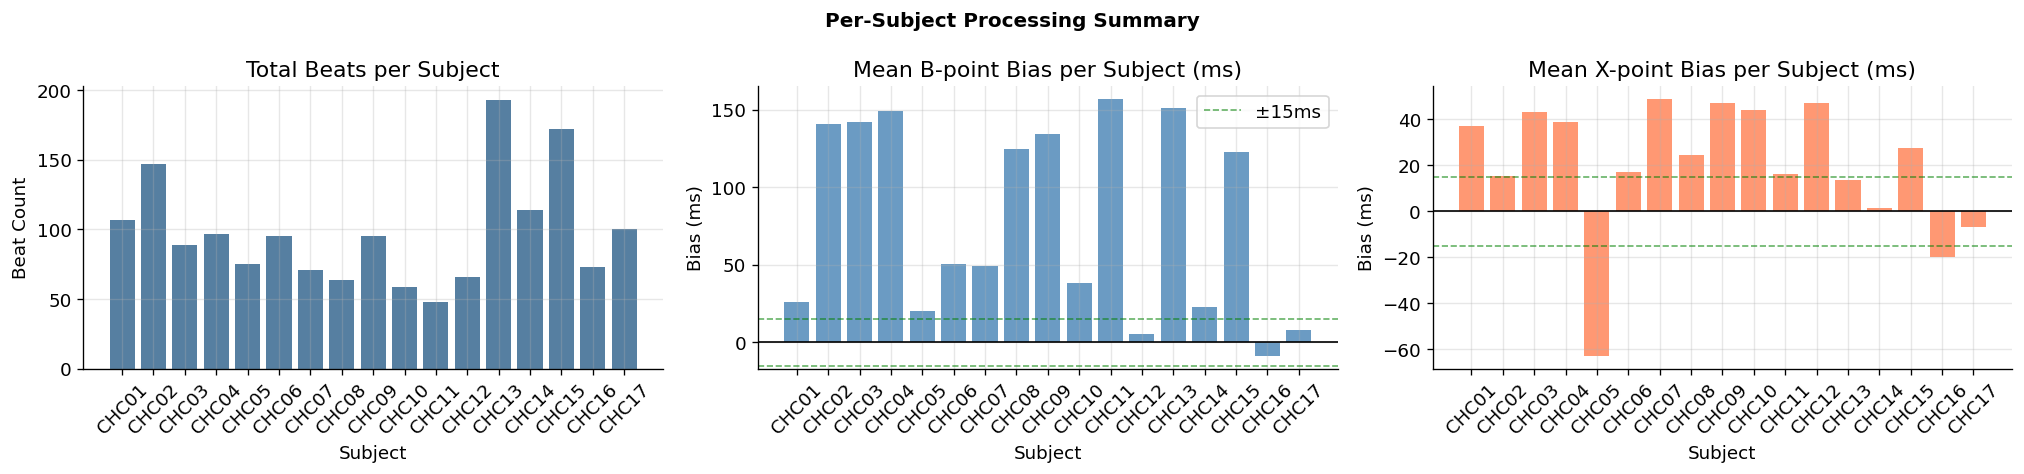

In [14]:
# Visualize per-subject processing results
ok = log_df[log_df['status'] == 'ok']
subj_summary = ok.groupby('subject_id').agg(
    n_records=('n_beats', 'count'),
    total_beats=('n_beats', 'sum'),
    mean_b_bias=('mean_b_bias_ms', 'mean'),
    mean_x_bias=('mean_x_bias_ms', 'mean'),
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
fig.suptitle('Per-Subject Processing Summary', fontsize=12, fontweight='bold')

axes[0].bar(subj_summary['subject_id'], subj_summary['total_beats'], color='#2C5F8A', alpha=0.8)
axes[0].set_title('Total Beats per Subject')
axes[0].set_xlabel('Subject')
axes[0].set_ylabel('Beat Count')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(subj_summary['subject_id'], subj_summary['mean_b_bias'], color='steelblue', alpha=0.8)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].axhline(15, color='green', linewidth=1, linestyle='--', alpha=0.6, label='±15ms')
axes[1].axhline(-15, color='green', linewidth=1, linestyle='--', alpha=0.6)
axes[1].set_title('Mean B-point Bias per Subject (ms)')
axes[1].set_xlabel('Subject')
axes[1].set_ylabel('Bias (ms)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

axes[2].bar(subj_summary['subject_id'], subj_summary['mean_x_bias'], color='coral', alpha=0.8)
axes[2].axhline(0, color='black', linewidth=1)
axes[2].axhline(15, color='green', linewidth=1, linestyle='--', alpha=0.6, label='±15ms')
axes[2].axhline(-15, color='green', linewidth=1, linestyle='--', alpha=0.6)
axes[2].set_title('Mean X-point Bias per Subject (ms)')
axes[2].set_xlabel('Subject')
axes[2].set_ylabel('Bias (ms)')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [15]:
# Verify a saved .npz file
saved_files = list(Path(OUTPUT_PREP_DIR).glob('*.npz'))
print(f'Total .npz files saved: {len(saved_files)}')


if saved_files:
    test_npz = np.load(saved_files[0], allow_pickle=True)
    print(f'\nVerifying: {saved_files[0].name}')
    for key in test_npz.files:
        val = test_npz[key]
        print(f'  {key:20s}: shape={val.shape}  dtype={val.dtype}')


print('\n✅ STEP 2 COMPLETE')
print('   All records preprocessed and saved as .npz files')
print('   NEXT: Run Notebook 03 — Build Final ML Dataset')

Total .npz files saved: 212

Verifying: CHC01_s0000058.npz
  icg_windows         : shape=(5, 200)  dtype=float32
  ecg_windows         : shape=(5, 200)  dtype=float32
  multimodal          : shape=(5, 2, 200)  dtype=float32
  labels              : shape=(5, 4)  dtype=float32
  icg_estimates       : shape=(5, 2)  dtype=float32
  biases              : shape=(5, 4)  dtype=float32
  cp_indices          : shape=(5, 3)  dtype=int32
  r_times             : shape=(5,)  dtype=float32
  subject_id          : shape=()  dtype=<U5
  record_id           : shape=()  dtype=<U8

✅ STEP 2 COMPLETE
   All records preprocessed and saved as .npz files
   NEXT: Run Notebook 03 — Build Final ML Dataset


In [16]:
# Recheck corrected timing and bias ranges for selected subjects
selected_subjects = {'CHC01', 'CHC13', 'CHC14', 'CHC15'}
subject_rows = []

for saved_path in Path(OUTPUT_PREP_DIR).glob('*.npz'):
    record = np.load(saved_path, allow_pickle=True)
    subject_id = str(record['subject_id'])
    if subject_id not in selected_subjects:
        continue
    labels = record['labels']
    estimates = record['icg_estimates']
    biases = record['biases']
    valid = ~np.isnan(biases).all(axis=1)
    for row in range(len(labels)):
        if valid[row]:
            subject_rows.append({
                'subject_id': subject_id,
                'icg_pep_ms': estimates[row, 0],
                'icg_lvet_ms': estimates[row, 1],
                'b_bias_ms': biases[row, 0],
                'x_bias_ms': biases[row, 1],
                'pep_bias_ms': biases[row, 2],
                'lvet_bias_ms': biases[row, 3],
            })

selected_df = pd.DataFrame(subject_rows)
print('Selected-subject corrected timing and bias summary:')
for subject_id, group in selected_df.groupby('subject_id'):
    print(
        f'{subject_id}: n={len(group)} | '
        f'icg_pep={group["icg_pep_ms"].mean():.1f}ms '
        f'[{group["icg_pep_ms"].min():.1f}, {group["icg_pep_ms"].max():.1f}] | '
        f'icg_lvet={group["icg_lvet_ms"].mean():.1f}ms '
        f'[{group["icg_lvet_ms"].min():.1f}, {group["icg_lvet_ms"].max():.1f}] | '
        f'bias means [B, X, PEP, LVET]='
        f'[{group["b_bias_ms"].mean():.1f}, {group["x_bias_ms"].mean():.1f}, '
        f'{group["pep_bias_ms"].mean():.1f}, {group["lvet_bias_ms"].mean():.1f}]ms'
    )

Selected-subject corrected timing and bias summary:
CHC01: n=87 | icg_pep=75.8ms [50.1, 175.1] | icg_lvet=269.9ms [175.1, 300.1] | bias means [B, X, PEP, LVET]=[22.9, 38.3, -72.2, 131.2]ms
CHC13: n=151 | icg_pep=188.6ms [60.4, 196.5] | icg_lvet=153.0ms [30.2, 317.2] | bias means [B, X, PEP, LVET]=[150.3, 14.8, 150.3, -132.6]ms
CHC14: n=83 | icg_pep=92.2ms [50.3, 196.6] | icg_lvet=247.7ms [30.2, 342.4] | bias means [B, X, PEP, LVET]=[22.2, 1.3, 22.2, -16.9]ms
CHC15: n=154 | icg_pep=159.2ms [50.4, 196.6] | icg_lvet=149.8ms [10.1, 312.1] | bias means [B, X, PEP, LVET]=[123.9, 28.2, 123.9, -97.6]ms


In [17]:
# Reprocess CHC01 and CHC14 after tightening AVC matching to <400ms
import contextlib
import io

rerun_subjects = {'CHC01', 'CHC14'}
rerun_rows = usable[usable['subject_id'].isin(rerun_subjects)]
for _, row in rerun_rows.iterrows():
    with contextlib.redirect_stdout(io.StringIO()):
        process_single_record(row['filepath'], save_dir=OUTPUT_PREP_DIR, verbose=False)

rerun_rows_out = []
for saved_path in Path(OUTPUT_PREP_DIR).glob('*.npz'):
    record = np.load(saved_path, allow_pickle=True)
    subject_id = str(record['subject_id'])
    if subject_id not in rerun_subjects:
        continue
    biases = record['biases']
    estimates = record['icg_estimates']
    valid = ~np.isnan(biases).all(axis=1)
    for row in range(len(biases)):
        if valid[row]:
            rerun_rows_out.append({
                'subject_id': subject_id,
                'icg_pep_ms': estimates[row, 0],
                'icg_lvet_ms': estimates[row, 1],
                'x_bias_ms': biases[row, 1],
                'lvet_bias_ms': biases[row, 3],
            })

rerun_df = pd.DataFrame(rerun_rows_out)
print('Post-400ms AVC-match summary:')
for subject_id, group in rerun_df.groupby('subject_id'):
    print(
        f'{subject_id}: n={len(group)} | '
        f'icg_pep={group["icg_pep_ms"].mean():.1f}ms | '
        f'icg_lvet={group["icg_lvet_ms"].mean():.1f}ms | '
        f'X-bias={group["x_bias_ms"].mean():.1f}ms | '
        f'LVET-bias={group["lvet_bias_ms"].mean():.1f}ms'
    )

Post-400ms AVC-match summary:
CHC01: n=87 | icg_pep=75.8ms | icg_lvet=269.9ms | X-bias=38.3ms | LVET-bias=131.2ms
CHC14: n=83 | icg_pep=92.2ms | icg_lvet=247.7ms | X-bias=1.3ms | LVET-bias=-16.9ms


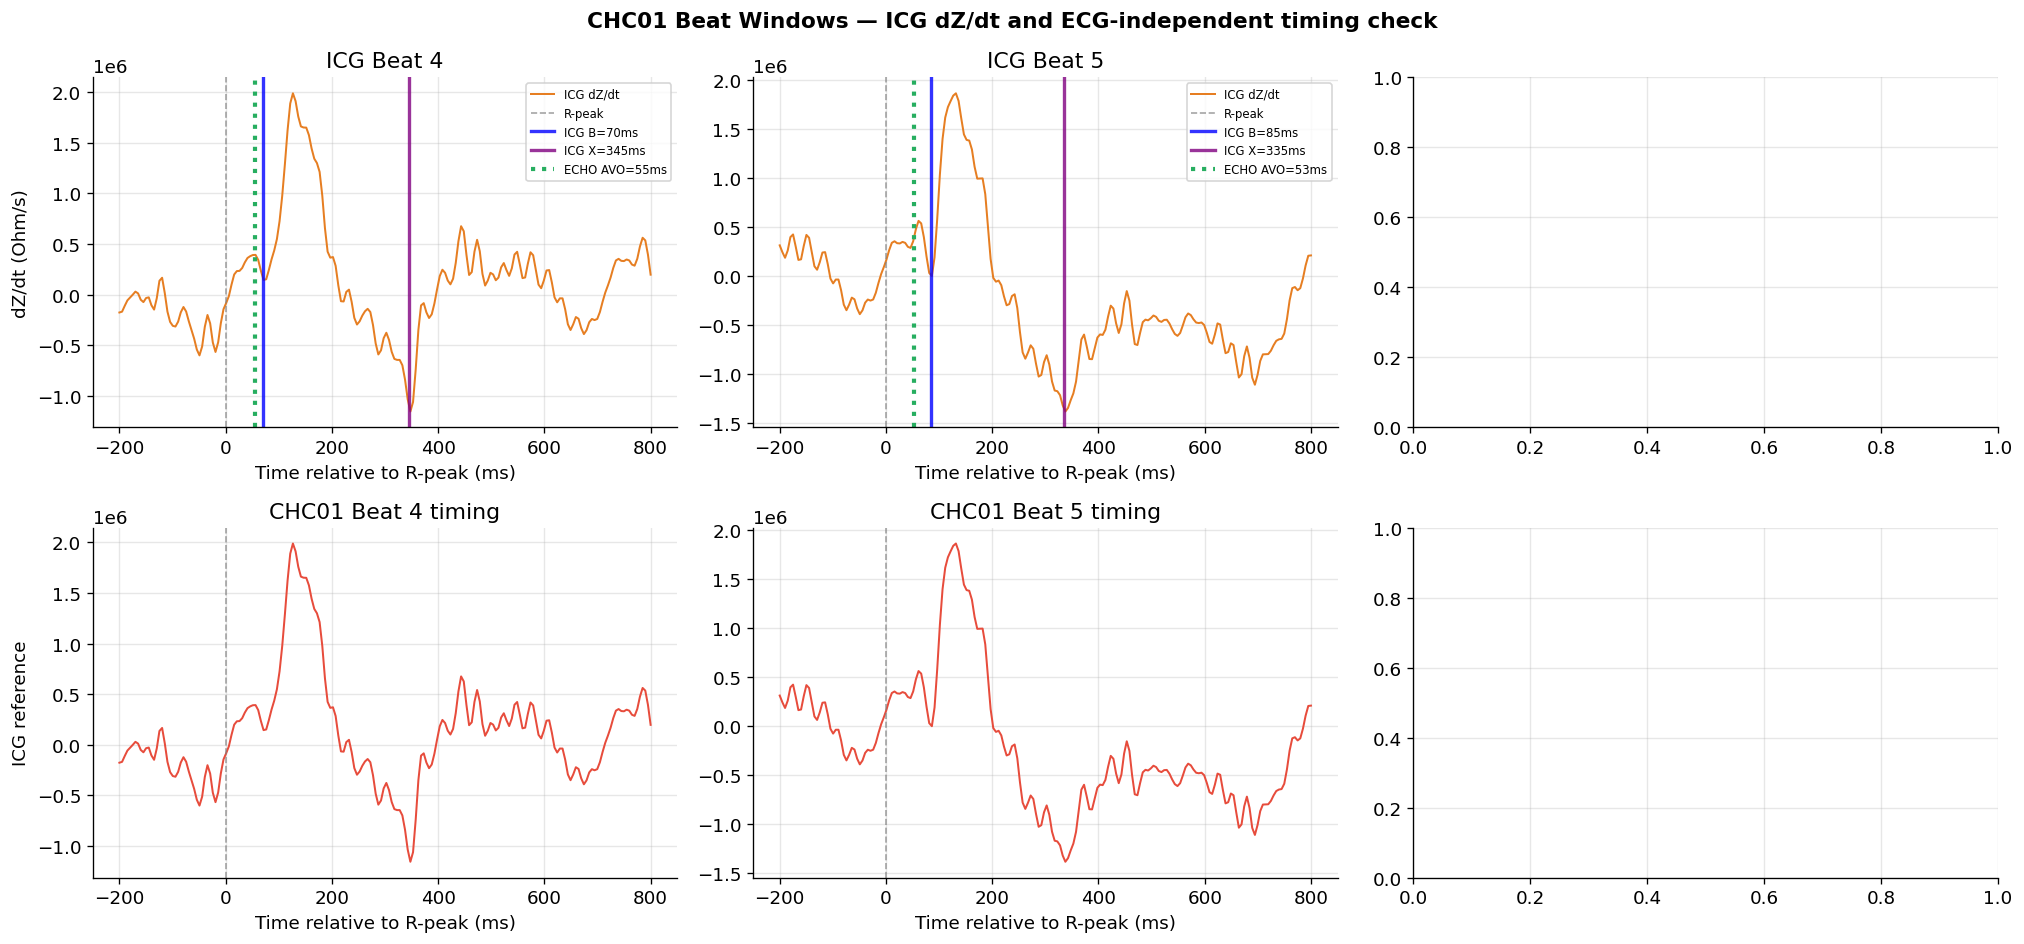

RR intervals (ms): [708.05237 708.05237 703.0305  723.11743]
Mean HR (bpm): 84.44006446732298


In [18]:
# Final subject-level diagnostic: CHC01 beat plot and RR check
chc01_path = usable.loc[usable['subject_id'] == 'CHC01', 'filepath'].iloc[0]

with h5py.File(chc01_path, 'r') as f:
    icg_raw_chc01 = f['measure']['value']['_031']['value']['data']['value'][()]
    icg_time_chc01 = f['measure']['value']['_031']['value']['time']['value'][()]
    r_data_chc01 = f['measure']['value']['_032']['value']['data']['value'][()]
    avo_chc01 = f['measure']['value']['_093']['value']['data']['value'][()].flatten().astype(np.float64) * 1000.0
    avc_chc01 = f['measure']['value']['_095']['value']['data']['value'][()].flatten().astype(np.float64) * 1000.0

icg_chc01 = icg_raw_chc01[0] if icg_raw_chc01.ndim == 2 else icg_raw_chc01
t_chc01 = (icg_time_chc01[0] if icg_time_chc01.ndim == 2 else icg_time_chc01).astype(np.float64) * 1000.0
r_peaks_chc01 = r_data_chc01.flatten().astype(np.float64) * 1000.0

dt_chc01_s = np.mean(np.diff(t_chc01)) / 1000.0
dzdt_chc01 = np.gradient(icg_chc01, dt_chc01_s)
dzdt_chc01_f = preprocess_signal(dzdt_chc01, FS_NICCOMO)

win_pre_chc01 = int(PRE_R_MS * FS_NICCOMO / 1000)
win_post_chc01 = int(POST_R_MS * FS_NICCOMO / 1000)
win_len_chc01 = win_pre_chc01 + win_post_chc01
t_window_chc01 = np.linspace(-PRE_R_MS, POST_R_MS, win_len_chc01)
beat_indices_chc01 = [len(r_peaks_chc01) // 2 + offset for offset in range(3)]

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
fig.suptitle('CHC01 Beat Windows — ICG dZ/dt and ECG-independent timing check', fontsize=13, fontweight='bold')

for col_i, bi in enumerate(beat_indices_chc01):
    r_ms_chc01 = r_peaks_chc01[bi]
    r_idx_chc01 = np.searchsorted(t_chc01, r_ms_chc01)
    start_chc01 = r_idx_chc01 - win_pre_chc01
    end_chc01 = r_idx_chc01 + win_post_chc01
    if start_chc01 < 0 or end_chc01 > len(dzdt_chc01_f):
        continue

    icg_win_chc01 = dzdt_chc01_f[start_chc01:end_chc01]
    b_lo_chc01 = win_pre_chc01 + int(0.05 * FS_NICCOMO)
    b_hi_chc01 = win_pre_chc01 + int(0.20 * FS_NICCOMO)
    x_lo_chc01 = win_pre_chc01 + int(0.20 * FS_NICCOMO)
    x_hi_chc01 = win_pre_chc01 + int(0.50 * FS_NICCOMO)
    icg_b_rel_chc01 = (np.argmin(icg_win_chc01[b_lo_chc01:b_hi_chc01]) + b_lo_chc01 - win_pre_chc01) * (1000 / FS_NICCOMO)
    icg_x_rel_chc01 = (np.argmin(icg_win_chc01[x_lo_chc01:x_hi_chc01]) + x_lo_chc01 - win_pre_chc01) * (1000 / FS_NICCOMO)

    gt_avo_rel_chc01 = None
    gt_avc_rel_chc01 = None
    if len(avo_chc01):
        diffs = np.abs(avo_chc01 - r_ms_chc01)
        nearest = np.argmin(diffs)
        if diffs[nearest] < 500:
            gt_avo_rel_chc01 = float(avo_chc01[nearest] - r_ms_chc01)
    if len(avc_chc01):
        diffs = np.abs(avc_chc01 - r_ms_chc01)
        nearest = np.argmin(diffs)
        if diffs[nearest] < 400:
            gt_avc_rel_chc01 = float(avc_chc01[nearest] - r_ms_chc01)

    ax = axes[0, col_i]
    ax.plot(t_window_chc01, icg_win_chc01, color='#E67E22', linewidth=1.2, label='ICG dZ/dt')
    ax.axvline(0, color='gray', linewidth=1, linestyle='--', alpha=0.7, label='R-peak')
    ax.axvline(icg_b_rel_chc01, color='blue', linewidth=2, label=f'ICG B={icg_b_rel_chc01:.0f}ms', alpha=0.8)
    ax.axvline(icg_x_rel_chc01, color='purple', linewidth=2, label=f'ICG X={icg_x_rel_chc01:.0f}ms', alpha=0.8)
    if gt_avo_rel_chc01 is not None:
        ax.axvline(gt_avo_rel_chc01, color='#27AE60', linewidth=2.5, linestyle=':', label=f'ECHO AVO={gt_avo_rel_chc01:.0f}ms')
    if gt_avc_rel_chc01 is not None:
        ax.axvline(gt_avc_rel_chc01, color='#E74C3C', linewidth=2.5, linestyle=':', label=f'ECHO AVC={gt_avc_rel_chc01:.0f}ms')
    ax.set_xlabel('Time relative to R-peak (ms)')
    ax.set_title(f'ICG Beat {bi + 1}')
    if col_i == 0:
        ax.set_ylabel('dZ/dt (Ohm/s)')
    ax.legend(fontsize=7, loc='upper right')

    axes[1, col_i].plot(t_window_chc01, icg_win_chc01, color='#E74C3C', linewidth=1.2)
    axes[1, col_i].axvline(0, color='gray', linewidth=1, linestyle='--', alpha=0.7)
    axes[1, col_i].set_xlabel('Time relative to R-peak (ms)')
    axes[1, col_i].set_title(f'CHC01 Beat {bi + 1} timing')
    if col_i == 0:
        axes[1, col_i].set_ylabel('ICG reference')

plt.tight_layout()
plt.show()

from pathlib import Path
f = sorted(Path('./output/preprocessed').glob('CHC01_*.npz'))[0]
d = np.load(f, allow_pickle=True)
print('RR intervals (ms):', np.diff(d['r_times']))
print('Mean HR (bpm):', 60000 / np.mean(np.diff(d['r_times'])))

In [19]:
# Compare CHC14 heart rate against the final CHC01 diagnostic
chc14_path = sorted(Path('./output/preprocessed').glob('CHC14_*.npz'))[0]
d14 = np.load(chc14_path, allow_pickle=True)
rr_chc14 = np.diff(d14['r_times'])
print('CHC14 RR intervals (ms):', rr_chc14)
print('CHC14 Mean HR (bpm):', 60000 / np.mean(rr_chc14))

CHC14 RR intervals (ms): [866.17957 886.32336 881.2875  911.5029  971.9341  951.7905  921.5747 ]
CHC14 Mean HR (bpm): 65.72160218601344
